Mounted at /content/drive
            N   S   E
strategy             
MA        291  50  25
ROC       349  91  26
BB        445  70   8


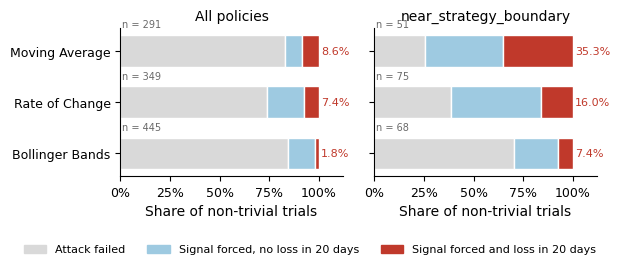

Non-trivial successes: 211
  no effect at either horizon : 38.9%
  same sign at both horizons  : 31.8%
  opposite sign               : 14.2%
  effect at one horizon only  : 15.2%
  same sign among attacks with an effect at both horizons: 69.1%
             n  same_sign
strategy                 
BB        70.0      0.871
MA        50.0      0.580
ROC       91.0      0.615


/tmp/ipykernel_417/4000751051.py:150: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(succ.groupby("strategy").apply(


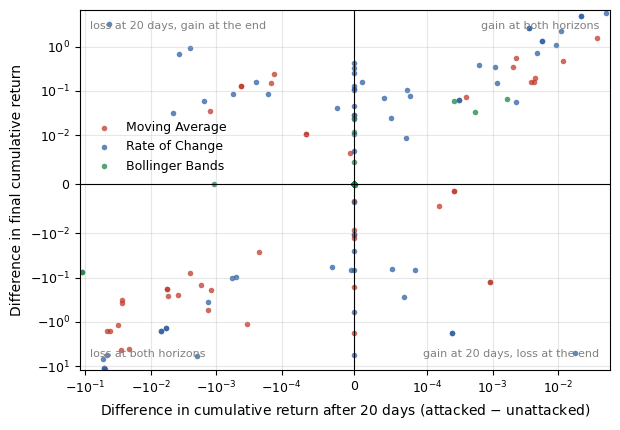

setup                                LSTM13y_All_MA
timing_policy                               uniform
objective                                 force_buy
attack_day                                       30
min_delta_norm                                 1.85
delta_cumulative_return_in_period         -0.045837
delta_final_cr                            -1.588517
Name: 432, dtype: object


NameError: name 'ALL_TICKERS' is not defined

In [1]:
# =============================================================================
# Plots for Section 5.3.2 (From Signal Changes to Economic Damage)
#
# Cells 1-3: add at the end of targeted_results.ipynb (they only read the CSVs).
# Cell 4:    add at the end of targeted_experiment_run.ipynb (it re-runs one
#            attack, so it needs MODEL_FOLDERS, DATA_FOLDER, ATTACK_START, ...).
# Every figure is saved as PDF in COMPARISON_DIR, ready for figures/ of the thesis.
# =============================================================================


# %% ---------------------------------------------------------------------------
# Cell 1 - common setup: load the held-out run (*_3) and keep the useful trials
# ------------------------------------------------------------------------------
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

import os
import sys
from pathlib import Path


PROJECT_ROOT = Path("/content/drive/MyDrive/master-thesis").resolve()

SRC_PATH = PROJECT_ROOT / "src"
NOTEBOOK_DIR = PROJECT_ROOT / "notebooks"

os.chdir(PROJECT_ROOT)

sys.path.append(str(PROJECT_ROOT))
sys.path.append(str(SRC_PATH))

RUN_DIR = NOTEBOOK_DIR / "results_targeted/with_validation_time"
RUN_SUFFIX = "_3"
COMPARISON_DIR = NOTEBOOK_DIR / "plots/economic"
os.makedirs(COMPARISON_DIR, exist_ok=True)

STRATEGY_ORDER = ["MA", "ROC", "BB"]
STRATEGY_NAMES = {"MA": "Moving Average", "ROC": "Rate of Change", "BB": "Bollinger Bands"}
STRATEGY_COLORS = {"MA": "#c0392b", "ROC": "#2e5fa3", "BB": "#1e8449"}

mpl.rcParams.update({
    "font.size": 10, "axes.labelsize": 10, "legend.fontsize": 9,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "pdf.fonttype": 42,
})

frames = []
for s in STRATEGY_ORDER:
    path = RUN_DIR / f"ALL_LSTM_{s}{RUN_SUFFIX}" / f"ALL_LSTM_{s}.csv"
    df = pd.read_csv(path)
    df["strategy"] = s
    frames.append(df)
trials = pd.concat(frames, ignore_index=True)

trials = trials[trials["valid"].astype(bool)].copy()
trials["success"] = trials["success"].astype(bool)
trials["already_target"] = trials["already_target"].astype(bool)
trials["nontrivial"] = ~trials["already_target"]
trials["nt_success"] = trials["success"] & trials["nontrivial"]
trials["harmful"] = trials["nt_success"] & (trials["delta_cumulative_return_in_period"] < 0)

# Sanity check against Table tab:held-out-overview (N, S, E per strategy)
check = trials[trials["nontrivial"]].groupby("strategy").agg(
    N=("nontrivial", "size"), S=("nt_success", "sum"), E=("harmful", "sum"))
print(check.loc[STRATEGY_ORDER])   # expected: MA 291/50/25, ROC 349/91/26, BB 445/70/8


# %% ---------------------------------------------------------------------------
# Cell 2 - Figure: from forced signal to economic damage (stacked bars)
#   For each strategy, the non-trivial trials split into: attack failed,
#   signal forced without loss within 20 days, signal forced with a loss.
#   Two groups: all timing policies, and near_strategy_boundary only.
# ------------------------------------------------------------------------------
def outcome_shares(df):
    nt = df[df["nontrivial"]]
    n = len(nt)
    failed = (~nt["nt_success"]).sum()
    harmful = nt["harmful"].sum()
    forced_no_loss = nt["nt_success"].sum() - harmful
    return n, np.array([failed, forced_no_loss, harmful]) / n

groups = [
    ("All policies", trials),
    ("near_strategy_boundary", trials[trials["timing_policy"] == "near_strategy_boundary"]),
]
parts = ["Attack failed", "Signal forced, no loss in 20 days", "Signal forced and loss in 20 days"]
part_colors = ["#d9d9d9", "#9ecae1", "#c0392b"]

fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.6), sharey=True)
for ax, (title, df) in zip(axes, groups):
    labels = []
    for i, s in enumerate(STRATEGY_ORDER):
        n, shares = outcome_shares(df[df["strategy"] == s])
        left = 0.0
        for share, color in zip(shares, part_colors):
            ax.barh(i, share * 100, left=left, color=color, edgecolor="white", height=0.62)
            left += share * 100
        # label of the last segment (harmful share)
        ax.text(101, i, f"{shares[2] * 100:.1f}%", va="center", ha="left", fontsize=8, color="#c0392b")
        ax.text(1, i - 0.42, f"n = {n}", va="bottom", ha="left", fontsize=7, color="dimgray")
        labels.append(STRATEGY_NAMES[s])
    ax.set_yticks(range(len(STRATEGY_ORDER)))
    ax.set_yticklabels(labels)
    ax.set_xlim(0, 112)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_xticklabels(["0%", "25%", "50%", "75%", "100%"])
    ax.set_xlabel("Share of non-trivial trials")
    ax.set_title(title, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].invert_yaxis()   # once: the y axis is shared
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in part_colors]
fig.legend(handles, parts, loc="lower center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, -0.04), fontsize=8)
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(COMPARISON_DIR / "decision_to_damage.pdf", bbox_inches="tight")
plt.show()


# %% ---------------------------------------------------------------------------
# Cell 3 - Figure: 20-day effect vs final effect of each successful attack,
#          and the agreement between their signs (closes the TODO in 5.3.2)
# ------------------------------------------------------------------------------
succ = trials[trials["nt_success"]].copy()
x = succ["delta_cumulative_return_in_period"].to_numpy()
y = succ["delta_final_cr"].to_numpy()

# Sign agreement. Values below EPS in absolute value are treated as zero: a forced signal
# that changes no trade can still leave a tiny difference (e.g. the fixed fee of an order of 0 shares).
EPS = 1e-6
sx = np.sign(np.where(np.abs(x) < EPS, 0, x))
sy = np.sign(np.where(np.abs(y) < EPS, 0, y))
both_zero = (sx == 0) & (sy == 0)
same_sign = (sx == sy) & (sx != 0)
opposite = (sx * sy) < 0
one_zero = ~both_zero & ((sx == 0) | (sy == 0))
print(f"Non-trivial successes: {len(succ)}")
print(f"  no effect at either horizon : {both_zero.mean():.1%}")
print(f"  same sign at both horizons  : {same_sign.mean():.1%}")
print(f"  opposite sign               : {opposite.mean():.1%}")
print(f"  effect at one horizon only  : {one_zero.mean():.1%}")
nonzero = ~both_zero & ~one_zero
if nonzero.any():
    print(f"  same sign among attacks with an effect at both horizons: {same_sign[nonzero].mean():.1%}")
print(succ.groupby("strategy").apply(
    lambda d: pd.Series({
        "n": len(d),
        "same_sign": (np.sign(d["delta_cumulative_return_in_period"]) == np.sign(d["delta_final_cr"])).mean(),
    })).round(3))

# Symmetric log scales: many values are exactly zero and a few are very large
LINTHRESH_X, LINTHRESH_Y = 1e-4, 1e-2
fig, ax = plt.subplots(figsize=(6.3, 4.4))
for s in STRATEGY_ORDER:
    d = succ[succ["strategy"] == s]
    ax.scatter(d["delta_cumulative_return_in_period"], d["delta_final_cr"],
               s=16, alpha=0.75, color=STRATEGY_COLORS[s], label=STRATEGY_NAMES[s], linewidths=0)
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xscale("symlog", linthresh=LINTHRESH_X)
ax.set_yscale("symlog", linthresh=LINTHRESH_Y)
ax.set_xlabel("Difference in cumulative return after 20 days (attacked $-$ unattacked)")
ax.set_ylabel("Difference in final cumulative return")
ax.grid(True, alpha=0.3)
# quadrant annotations
ax.text(0.98, 0.97, "gain at both horizons", transform=ax.transAxes, ha="right", va="top", fontsize=8, color="gray")
ax.text(0.02, 0.03, "loss at both horizons", transform=ax.transAxes, ha="left", va="bottom", fontsize=8, color="gray")
ax.text(0.02, 0.97, "loss at 20 days, gain at the end", transform=ax.transAxes, ha="left", va="top", fontsize=8, color="gray")
ax.text(0.98, 0.03, "gain at 20 days, loss at the end", transform=ax.transAxes, ha="right", va="bottom", fontsize=8, color="gray")
ax.legend(loc="center left", bbox_to_anchor=(0.0, 0.62), frameon=False)
fig.tight_layout()
fig.savefig(COMPARISON_DIR / "delta_cr_20d_vs_final.pdf", bbox_inches="tight")
plt.show()


# %% ---------------------------------------------------------------------------
# Cell 4 - Figure: example of a single harmful attack (cumulative return with
#          and without the attack). Add to targeted_experiment_run.ipynb.
#          Works for the fixed regimes (model_variant="single").
# ------------------------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from notebooks.targeted_experiment_utils import ATSSetup   # ALL_TICKERS, MODEL_FOLDERS, ... come from the notebook
from notebooks.targeted_experiment_utils import (
    get_predictions_and_actuals, get_ticker_data, predict_ticker,
    volatility_perturbation, attack_signal_day, CLOSE_FEATURE_INDEX,
)
from scr.trade.backtest import simulate_trades_with_allocation
from notebooks.utils import calculate_cumulative_returns

EXAMPLE_DIR = NOTEBOOK_DIR / "plots/economic"
EXAMPLE_DIR.mkdir(parents=True, exist_ok=True)

# 1) Pick the trial: by default the harmful MA attack on LSTM-13y with the largest final loss
res = pd.read_csv(NOTEBOOK_DIR / "results_targeted/with_validation_time/ALL_LSTM_MA_3/ALL_LSTM_MA.csv")
res = res[res["valid"].astype(bool) & res["success"].astype(bool) & ~res["already_target"].astype(bool)]
res = res[(res["model"] == "LSTM") & (res["delta_cumulative_return_in_period"] < 0)]
row = res.sort_values("delta_final_cr").iloc[0]          # change the selection here if needed
print(row[["setup", "timing_policy", "objective", "attack_day", "min_delta_norm",
           "delta_cumulative_return_in_period", "delta_final_cr"]])

# 2) Rebuild the unattacked and the attacked run of that trial
setup = ATSSetup(row["setup"], tuple(ALL_TICKERS), row["strategy"], model_name=row["model"],
                 model_variant="single", attacked_ticker=row["attacked_ticker"])
mf = setup.model_folder(MODEL_FOLDERS)
d, k = int(row["attack_day"]), float(row["min_delta_norm"])

preds, acts = get_predictions_and_actuals(
    setup.tickers, mf, SEQUENCE_LENGTH, PROJECT_ROOT, DATA_FOLDER, model_variant="single",
    simulation_start=ATTACK_START, simulation_end=ATTACK_END, data_start=DATA_START,
    use_yahoo_api=USE_YAHOO_API)
sig_base = setup.strategy(preds, acts)
ret_base = simulate_trades_with_allocation(preds, acts, sig_base)

X = get_ticker_data(setup.attacked_ticker, SEQUENCE_LENGTH, PROJECT_ROOT, DATA_FOLDER,
                    simulation_start=ATTACK_START, simulation_end=ATTACK_END,
                    data_start=DATA_START, use_yahoo_api=USE_YAHOO_API)["X_test"].copy()
X[d, -1, CLOSE_FEATURE_INDEX] = volatility_perturbation(X[d, :, CLOSE_FEATURE_INDEX], k, vol_window=30)
pred_att = predict_ticker(setup.attacked_ticker, mf, SEQUENCE_LENGTH, PROJECT_ROOT, X_override=X,
                          data_folder=DATA_FOLDER, simulation_start=ATTACK_START, simulation_end=ATTACK_END,
                          data_start=DATA_START, use_yahoo_api=USE_YAHOO_API)
preds_att = {t: v.copy() for t, v in preds.items()}
preds_att[setup.attacked_ticker] = pred_att[: len(preds[setup.attacked_ticker])]
sig_att = setup.strategy(preds_att, acts)
ret_att = simulate_trades_with_allocation(preds_att, acts, sig_att)

eval_day = attack_signal_day(d, setup.strategy_name)
print("forced signal:", int(sig_base[setup.attacked_ticker][eval_day]), "->",
      int(sig_att[setup.attacked_ticker][eval_day]))

# 3) Plot the two cumulative returns and their difference
cr_base = calculate_cumulative_returns(ret_base)
cr_att = calculate_cumulative_returns(ret_att)
days = np.arange(len(cr_base))
fig, axes = plt.subplots(2, 1, figsize=(6.3, 4.6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(days, cr_base, color="black", linewidth=1.2, label="Unattacked ATS")
axes[0].plot(days, cr_att, color="#c0392b", linewidth=1.0, linestyle="--", label="Attacked ATS")
axes[0].axvline(eval_day, color="gray", linestyle=":", linewidth=1)
axes[0].set_ylabel("Cumulative returns (%)")
axes[0].legend(frameon=False, loc="upper left")
axes[0].grid(True, alpha=0.3)
axes[1].plot(days, cr_att - cr_base, color="#c0392b", linewidth=1.0)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].axvline(eval_day, color="gray", linestyle=":", linewidth=1)
axes[1].axvspan(eval_day, eval_day + 20, color="gray", alpha=0.15, linewidth=0)
axes[1].set_ylabel("Difference")
axes[1].set_xlabel("Trading days of the attack period (index of the signal series)")
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(EXAMPLE_DIR / "attack_example.pdf", bbox_inches="tight")
plt.show()